# Chapter 4. Implementation
## 4.6 Noise-Level Estimation
### 4.6.1 Noise Estimator Comparison and Selection
Three noise-level estimators are compared on 50 calibration images.


## 1. Experiment Setup

Laplacian, wavelet, and block-based estimators use the same calibration images and noise levels.


In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

# Find the project directory
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_dir) not in sys.path:
    sys.path.append(str(project_dir))

from src.noise import add_gaussian_noise
from src.noise_level_estimators import block_noise_estimate, laplacian_noise_estimate, wavelet_noise_estimate
from src.utils import load_grayscale_image


In [2]:
# Experiment settings
noise_levels = [2, 4, 6, 8, 10, 12, 15]
seed = 42
num_calibration = 50
n_jobs = 16

calibration_dir = project_dir / "data" / "calibration"
result_dir = project_dir / "results" / "Chapter4_CompareNoiseEstimators"
result_dir.mkdir(parents=True, exist_ok=True)

print("Noise levels (%):", noise_levels)
print("Random seed:", seed)
print("Parallel jobs:", n_jobs)


Noise levels (%): [2, 4, 6, 8, 10, 12, 15]
Random seed: 42
Parallel jobs: 16


In [3]:
# Find all image files
image_files = []
for pattern in ["*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff"]:
    image_files.extend(calibration_dir.glob(pattern))

image_files = sorted(image_files)
if len(image_files) < num_calibration:
    raise FileNotFoundError(
        f"At least {num_calibration} images are required, but only {len(image_files)} were found in {calibration_dir}"
    )

# Reproduce the calibration split
split_rng = np.random.default_rng(seed)
shuffled_indices = split_rng.permutation(len(image_files))
calibration_indices = shuffled_indices[:num_calibration]
calibration_files = sorted([image_files[index] for index in calibration_indices])

calibration_images = {
    image_file.stem: load_grayscale_image(image_file)
    for image_file in calibration_files
}

print("Number of calibration images:", len(calibration_images))
print("Calibration image IDs:")
print(", ".join(image_file.stem for image_file in calibration_files))


Number of calibration images: 50
Calibration image IDs:
004, 008, 009, 010, 021, 025, 026, 027, 030, 034, 038, 039, 047, 051, 052, 055, 057, 068, 071, 076, 080, 085, 093, 097, 102, 105, 107, 116, 122, 131, 134, 139, 145, 148, 149, 151, 153, 154, 158, 165, 172, 174, 177, 179, 188, 189, 190, 191, 197, 198


## 2. Estimator Evaluation

Each noisy image is passed to all three estimators. Estimates are reported as percentages.


In [4]:
# Evaluate all estimators on one image-noise case
def evaluate_estimators(image_name, clean_image, noise_percent):
    noisy_image = add_gaussian_noise(clean_image, sigma=noise_percent / 100, seed=seed).astype(np.float32)

    start = time.perf_counter()
    laplacian_sigma = float(laplacian_noise_estimate(noisy_image))
    laplacian_time = time.perf_counter() - start

    start = time.perf_counter()
    wavelet_sigma = float(wavelet_noise_estimate(noisy_image))
    wavelet_time = time.perf_counter() - start

    start = time.perf_counter()
    block_sigma = float(block_noise_estimate(noisy_image))
    block_time = time.perf_counter() - start

    estimates = np.array([laplacian_sigma, wavelet_sigma, block_sigma])
    if not np.all(np.isfinite(estimates)):
        raise ValueError(f"Non-finite estimate for {image_name} at {noise_percent}%.")

    return {
        "image": image_name,
        "true_sigma": noise_percent,
        "laplacian_estimate": laplacian_sigma * 100,
        "wavelet_estimate": wavelet_sigma * 100,
        "block_estimate": block_sigma * 100,
        "laplacian_time_ms": laplacian_time * 1000,
        "wavelet_time_ms": wavelet_time * 1000,
        "block_time_ms": block_time * 1000
    }


calibration_rows = Parallel(n_jobs=n_jobs, prefer="threads", verbose=5)(
    delayed(evaluate_estimators)(image_name, clean_image, noise_percent)
    for noise_percent in noise_levels
    for image_name, clean_image in calibration_images.items()
)

calibration_results = pd.DataFrame(calibration_rows)
print("Calibration cases:", len(calibration_results))


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:   11.8s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:   35.0s
[Parallel(n_jobs=16)]: Done 256 tasks      | elapsed:  1.1min


Calibration cases: 350


[Parallel(n_jobs=16)]: Done 350 out of 350 | elapsed:  1.5min finished


In [5]:
# Convert to one row per estimator and calibration case
estimator_columns = {
    "Laplacian": ("laplacian_estimate", "laplacian_time_ms"),
    "Wavelet": ("wavelet_estimate", "wavelet_time_ms"),
    "Block-based": ("block_estimate", "block_time_ms")
}

long_rows = []

for estimator_name, (estimate_column, time_column) in estimator_columns.items():
    current = calibration_results[["image", "true_sigma", estimate_column, time_column]].copy()
    current = current.rename(columns={estimate_column: "estimated_sigma", time_column: "runtime_ms"})
    current["estimator"] = estimator_name
    current["signed_error"] = current["estimated_sigma"] - current["true_sigma"]
    current["absolute_error"] = current["signed_error"].abs()
    current["squared_error"] = current["signed_error"] ** 2
    current["relative_error_percent"] = current["absolute_error"] / current["true_sigma"] * 100
    long_rows.append(current)

estimator_results = pd.concat(long_rows, ignore_index=True)


## 3. Results and Selection

MRE is the main comparison measure. MAE, RMSE, bias, and runtime are also reported.


In [6]:
# Summarise performance across all calibration cases
estimator_summary = (
    estimator_results.groupby("estimator", as_index=False)
    .agg(
        mean_relative_error=("relative_error_percent", "mean"),
        mae=("absolute_error", "mean"),
        rmse=("squared_error", lambda values: np.sqrt(values.mean())),
        bias=("signed_error", "mean"),
        mean_runtime_ms=("runtime_ms", "mean")
    )
    .sort_values("mean_relative_error")
    .reset_index(drop=True)
)

# Summarise performance at each noise level
noise_level_summary = (
    estimator_results.groupby(["true_sigma", "estimator"], as_index=False)
    .agg(
        mean_estimate=("estimated_sigma", "mean"),
        mae=("absolute_error", "mean"),
        bias=("signed_error", "mean"),
        mean_relative_error=("relative_error_percent", "mean")
    )
)

selected_estimator = estimator_summary.loc[0, "estimator"]
estimator_order = list(estimator_columns)

# Create tables for each noise level
mre_by_noise = (
    noise_level_summary.pivot(index="true_sigma", columns="estimator", values="mean_relative_error")
    .reindex(columns=estimator_order).reset_index()
    .rename(columns={"true_sigma": "Noise level (%)"})
)

estimate_by_noise = (
    noise_level_summary.pivot(index="true_sigma", columns="estimator", values="mean_estimate")
    .reindex(columns=estimator_order).reset_index()
    .rename(columns={"true_sigma": "True noise level (%)"})
)

estimator_summary_display = estimator_summary.rename(columns={
    "estimator": "Estimator",
    "mean_relative_error": "Overall MRE (%)",
    "mae": "MAE (pp)",
    "rmse": "RMSE (pp)",
    "bias": "Bias (pp)",
    "mean_runtime_ms": "Mean runtime (ms)"
})

print("\nOverall estimator performance:")
display(estimator_summary_display.round(2))

print("\nMean estimated noise level:")
display(estimate_by_noise.round(2))

print("\nMean relative error:")
display(mre_by_noise.round(2))



Overall estimator performance:


,Estimator,Overall MRE (%),MAE (pp),RMSE (pp),Bias (pp),Mean runtime (ms)
0,Laplacian,10.60,0.44,0.61,0.44,270.88
1,Block-based,10.98,0.91,1.25,-0.68,2515.40
2,Wavelet,11.26,0.46,0.69,0.46,953.76



Mean estimated noise level:


estimator,True noise level (%),Laplacian,Wavelet,Block-based
0,2,2.81,2.83,1.98
1,4,4.56,4.65,3.79
2,6,6.44,6.52,5.72
3,8,8.37,8.42,7.50
4,10,10.33,10.34,9.22
5,12,12.30,12.27,10.76
6,15,15.28,15.19,13.31



Mean relative error:


estimator,Noise level (%),Laplacian,Wavelet,Block-based
0,2,40.62,41.42,11.85
1,4,14.04,16.34,10.88
2,6,7.30,8.70,10.05
3,8,4.60,5.24,9.59
4,10,3.26,3.44,10.30
5,12,2.50,2.30,11.82
6,15,1.85,1.35,12.33


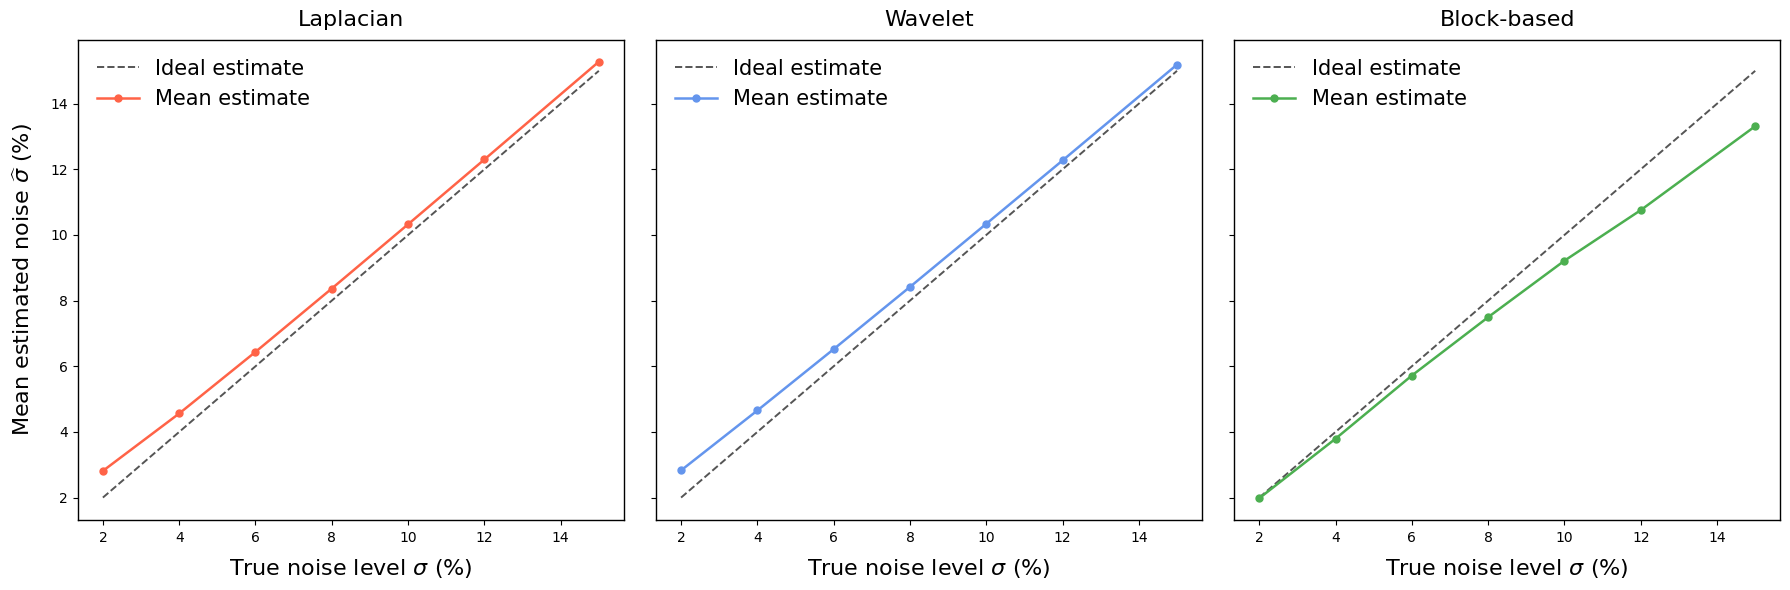

In [7]:
# Plot the three estimators against the ideal estimate
colours = {"Laplacian": "#ff6347", "Wavelet": "#6495ed", "Block-based": "#4caf50"}
estimator_order = list(estimator_columns)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

for ax, estimator_name in zip(axes, estimator_order):
    current = noise_level_summary[
        noise_level_summary["estimator"] == estimator_name
    ].sort_values("true_sigma")

    ax.plot(noise_levels, noise_levels, color="#555555", linestyle="--",
            linewidth=1.4, label="Ideal estimate")
    ax.plot(current["true_sigma"], current["mean_estimate"], marker="o",
            markersize=5, linewidth=1.8, color=colours[estimator_name],
            label="Mean estimate")

    ax.set_title(estimator_name, fontsize=16, pad=10)
    ax.set_xlabel(r"True noise level $\sigma$ (%)", fontsize=16, labelpad=9)
    ax.tick_params(axis="both", labelsize=10, pad=4)
    ax.legend(frameon=False, fontsize=15, loc="upper left")

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.0)

axes[0].set_ylabel(r"Mean estimated noise $\widehat{\sigma}$ (%)", fontsize=16, labelpad=11)

fig.tight_layout(w_pad=2.0)
fig.savefig(result_dir / "noise_estimator_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


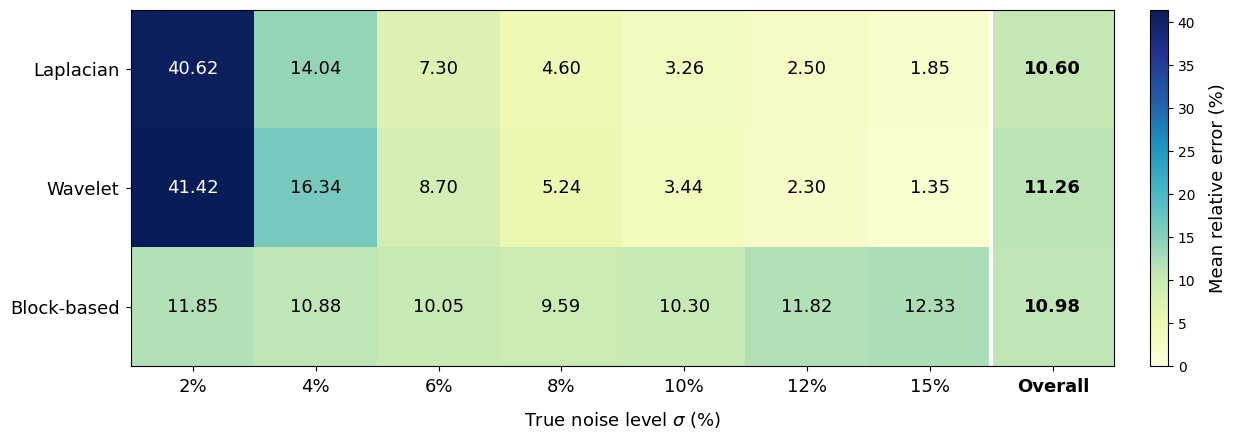

In [8]:
# Plot MRE at each noise level and the overall mean
heatmap_data = (
    noise_level_summary.pivot(
        index="estimator", columns="true_sigma", values="mean_relative_error"
    ).reindex(index=estimator_order, columns=noise_levels)
)
heatmap_data["Overall"] = heatmap_data.mean(axis=1)

fig, ax = plt.subplots(figsize=(13.5, 4.5))
image = ax.imshow(heatmap_data.values, cmap="YlGnBu", aspect="auto", vmin=0)

x_labels = [f"{value}%" for value in noise_levels] + ["Overall"]
ax.set_xticks(np.arange(len(x_labels)), labels=x_labels)
ax.set_yticks(np.arange(len(estimator_order)), labels=estimator_order)
ax.set_xlabel(r"True noise level $\sigma$ (%)", fontsize=13, labelpad=10)
ax.tick_params(axis="both", labelsize=13, pad=5)

# Separate the overall column
ax.axvline(len(noise_levels) - 0.5, color="white", linewidth=3)
ax.get_xticklabels()[-1].set_fontweight("bold")

maximum_mre = heatmap_data.to_numpy().max()

for row in range(len(estimator_order)):
    for column in range(len(x_labels)):
        value = heatmap_data.iloc[row, column]
        text_colour = "white" if value > maximum_mre * 0.55 else "black"
        ax.text(
            column, row, f"{value:.2f}", ha="center", va="center",
            color=text_colour, fontsize=13,
            fontweight="bold" if column == len(x_labels) - 1 else "normal"
        )

colour_bar = fig.colorbar(image, ax=ax, pad=0.03)
colour_bar.set_label("Mean relative error (%)", fontsize=13, labelpad=10)
colour_bar.ax.tick_params(labelsize=10)

fig.tight_layout()
fig.savefig(result_dir / "noise_estimator_mre_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
